In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO


In [21]:


columns = [
    "Line", "Station", "Alt", "Gravity", "SD",
    "TiltX", "TiltY", "Temp", "Tide", "Duration",
    "Rejected", "Time", "DecimalTime", "Terrain", "Date"
]

def read_gravity(filename):
    with open(filename, "r") as f:
        lines = [
            line for line in f
            if line.strip() and not line.lstrip().startswith("/")
        ]

    df = pd.read_csv(
        StringIO("".join(lines)),
        sep=r"\s+",
        names=columns
    )

    df["Date"] = df["Date"].astype(str).str.strip()

    for col in ["Line", "Station", "Gravity", "SD"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df[df["Date"] == "2026/10/17"].copy()

    return df


grid1 = read_gravity("../../Data/Gravity data/cg5_1/T095927.TXT")
grid2 = read_gravity("../../Data/Gravity data/cg5_2/T095903.TXT")

# Correct final five readings in Grid 2 to base station
mask = (
    (grid2["Line"] == 5) &
    (grid2["Station"] == 1) &
    (grid2["Time"] >= "16:30:28")
)

grid2.loc[mask, "Line"] = 0

print("Grid 1 total readings:", len(grid1))
print("Grid 2 total readings:", len(grid2))

display(grid1.head())
display(grid2.head())


Grid 1 total readings: 194
Grid 2 total readings: 181


,Line,Station,Alt,Gravity,SD,TiltX,TiltY,Temp,Tide,Duration,Rejected,Time,DecimalTime,Terrain,Date
0,0.0,0.0,0.0,3683.693,0.056,6.1,0.2,-1.69,0.016,30,0,10:41:06,46281.44450,0.0,2026/10/17
1,0.0,0.0,0.0,3683.692,0.038,7.1,-1.3,-1.68,0.016,30,0,10:41:49,46281.44499,0.0,2026/10/17
2,0.0,0.0,0.0,3683.722,0.094,-1.4,-17.8,-1.52,0.014,30,0,10:48:28,46281.44960,0.0,2026/10/17
3,0.0,0.0,0.0,3683.721,0.079,-0.1,-19.3,-1.51,0.013,30,0,10:49:11,46281.45010,0.0,2026/10/17
4,0.0,0.0,0.0,3683.720,0.028,2.0,-20.6,-1.50,0.013,30,0,10:49:45,46281.45049,0.0,2026/10/17


,Line,Station,Alt,Gravity,SD,TiltX,TiltY,Temp,Tide,Duration,Rejected,Time,DecimalTime,Terrain,Date
0,0.0,0.0,24.9510,3928.797,0.015,-5.7,-10.9,-6.71,0.014,60,2,10:48:14,46281.44944,0.0,2026/10/17
1,0.0,0.0,23.9744,3928.801,0.014,-6.4,3.8,-6.89,0.012,30,4,10:53:19,46281.45297,0.0,2026/10/17
2,0.0,0.0,23.7303,3928.801,0.013,-7.7,3.1,-6.91,0.012,30,9,10:54:03,46281.45347,0.0,2026/10/17
3,0.0,0.0,23.7303,3928.801,0.010,-8.6,2.7,-6.93,0.012,30,0,10:54:38,46281.45388,0.0,2026/10/17
4,1.0,1.0,22.7537,3929.465,0.014,-5.2,-21.6,-7.05,0.009,30,0,11:02:05,46281.45904,0.0,2026/10/17


In [22]:
# Correct Grid 2, Line 4 station numbering
mask = grid2["Line"] == 4

# Shift stations 0–10 to 1–11
grid2.loc[mask, "Station"] = grid2.loc[mask, "Station"] + 1

# Check station numbers
print(sorted(grid2.loc[mask, "Station"].unique()))


[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0)]


In [23]:

# Separate base station measurements
base1 = grid1[grid1["Line"] == 0].copy()
base2 = grid2[grid2["Line"] == 0].copy()

# Separate survey measurements
survey1 = grid1[grid1["Line"].between(1, 5)].copy()
survey2 = grid2[grid2["Line"].between(1, 5)].copy()

print("Grid 1 survey readings:", len(survey1))
print("Grid 2 survey readings:", len(survey2))

print("Grid 1 base readings:", len(base1))
print("Grid 2 base readings:", len(base2))


Grid 1 survey readings: 183
Grid 2 survey readings: 172
Grid 1 base readings: 11
Grid 2 base readings: 9


In [24]:

avg1 = survey1.groupby(
    ["Line", "Station"], as_index=False
).agg(
    Gravity=("Gravity", "mean"),
    SD=("SD", "mean"),
    Count=("Gravity", "count")
)

avg2 = survey2.groupby(
    ["Line", "Station"], as_index=False
).agg(
    Gravity=("Gravity", "mean"),
    SD=("SD", "mean"),
    Count=("Gravity", "count")
)

print("Grid 1 stations:", len(avg1))
print("Grid 2 stations:", len(avg2))

display(avg1.head())
display(avg2.head())


Grid 1 stations: 55
Grid 2 stations: 55


,Line,Station,Gravity,SD,Count
0,1.0,1.0,3683.523000,0.026000,3
1,1.0,2.0,3683.486333,0.025333,3
2,1.0,3.0,3683.454600,0.246200,5
3,1.0,4.0,3683.405333,0.053333,3
4,1.0,5.0,3683.425333,0.027333,3


,Line,Station,Gravity,SD,Count
0,1.0,1.0,3929.464667,0.012667,3
1,1.0,2.0,3929.415000,0.013667,3
2,1.0,3.0,3929.374333,0.021000,3
3,1.0,4.0,3929.317333,0.012667,3
4,1.0,5.0,3929.266667,0.022667,3


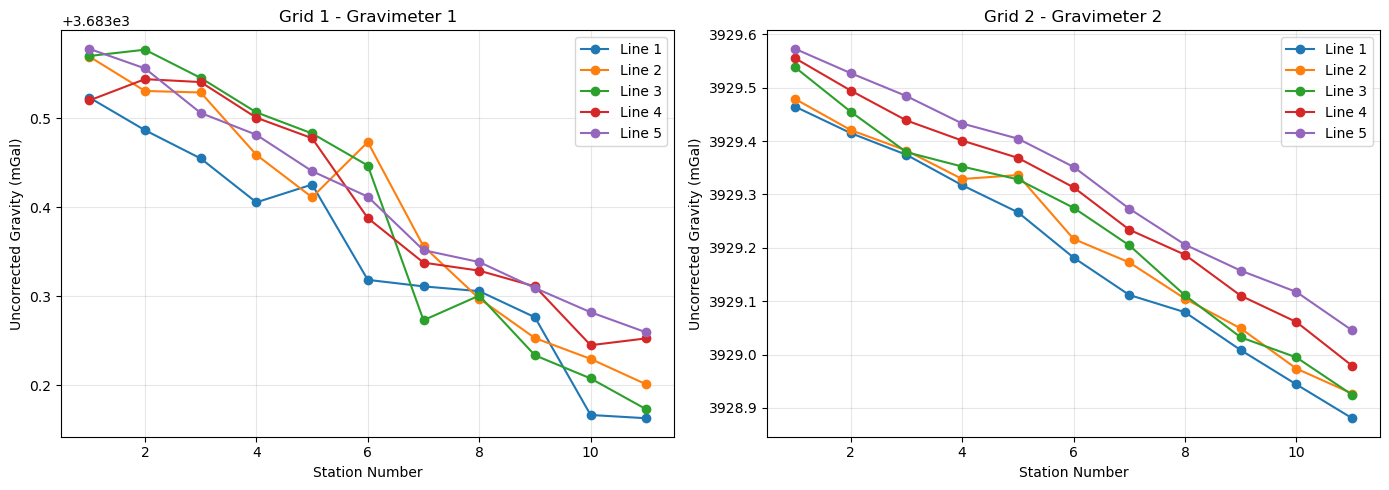

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for line, group in avg1.groupby("Line"):
    axes[0].plot(
        group["Station"],
        group["Gravity"],
        "o-",
        label=f"Line {int(line)}"
    )

for line, group in avg2.groupby("Line"):
    axes[1].plot(
        group["Station"],
        group["Gravity"],
        "o-",
        label=f"Line {int(line)}"
    )

for ax, title in zip(
    axes,
    ["Grid 1 - Gravimeter 1", "Grid 2 - Gravimeter 2"]
):
    ax.set_title(title)
    ax.set_xlabel("Station Number")
    ax.set_ylabel("Uncorrected Gravity (mGal)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


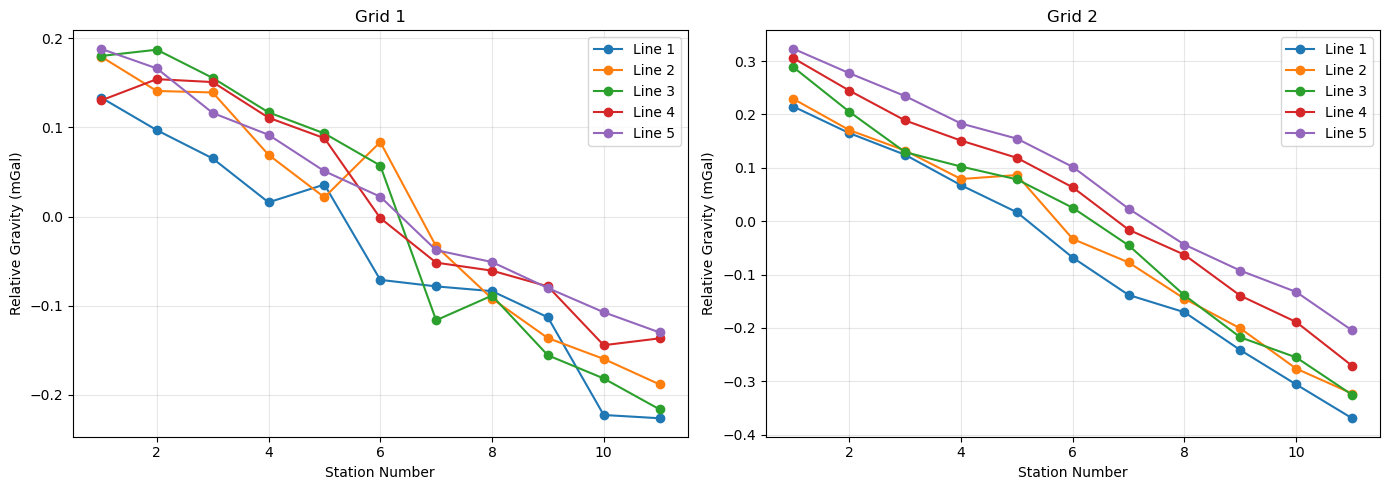

In [26]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, avg, title in zip(
    axes, [avg1, avg2], ["Grid 1", "Grid 2"]
):
    relative = avg.copy()
    relative["Relative"] = relative["Gravity"] - relative["Gravity"].mean()

    for line, group in relative.groupby("Line"):
        ax.plot(
            group["Station"], group["Relative"],
            "o-", label=f"Line {int(line)}"
        )

    ax.set_title(title)
    ax.set_xlabel("Station Number")
    ax.set_ylabel("Relative Gravity (mGal)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()
